In [1]:
import pandas as pd
import numpy as np
import shap
import joblib

import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(
    "../data/raw/career_dataset.csv"
)

print(df.shape)

(10000, 46)


In [3]:
TARGET = "placed"

drop_columns = [
    "student_id",
    "placed",
    "placement_role",
    "package_lpa",
    "preferred_role",
    "preferred_domain",
    "preferred_location",
    "remote_preference",
    "higher_studies_interest"
]

X = df.drop(
    columns=drop_columns
)

y = df[TARGET]

In [4]:
model_path = (
    "../models/"
    "placement_xgb_tuned_pipeline.pkl"
)

pipeline = joblib.load(
    model_path
)

print("Tuned model loaded successfully!")

Tuned model loaded successfully!


In [5]:
preprocessor = pipeline.named_steps[
    "preprocessor"
]

model = pipeline.named_steps[
    "model"
]

In [6]:
print(type(preprocessor))
print(type(model))

<class 'sklearn.compose._column_transformer.ColumnTransformer'>
<class 'xgboost.sklearn.XGBClassifier'>


In [7]:
X_transformed = preprocessor.transform(X)

In [8]:
print(
    "Transformed shape:",
    X_transformed.shape
)

Transformed shape: (10000, 53)


In [9]:
feature_names = (
    preprocessor
    .get_feature_names_out()
)

print(
    "Number of features:",
    len(feature_names)
)

Number of features: 53


In [10]:
explainer = shap.TreeExplainer(
    model
)

In [11]:
sample_size = min(
    1000,
    X_transformed.shape[0]
)

X_sample = X_transformed[
    :sample_size
]

shap_values = explainer.shap_values(
    X_sample
)

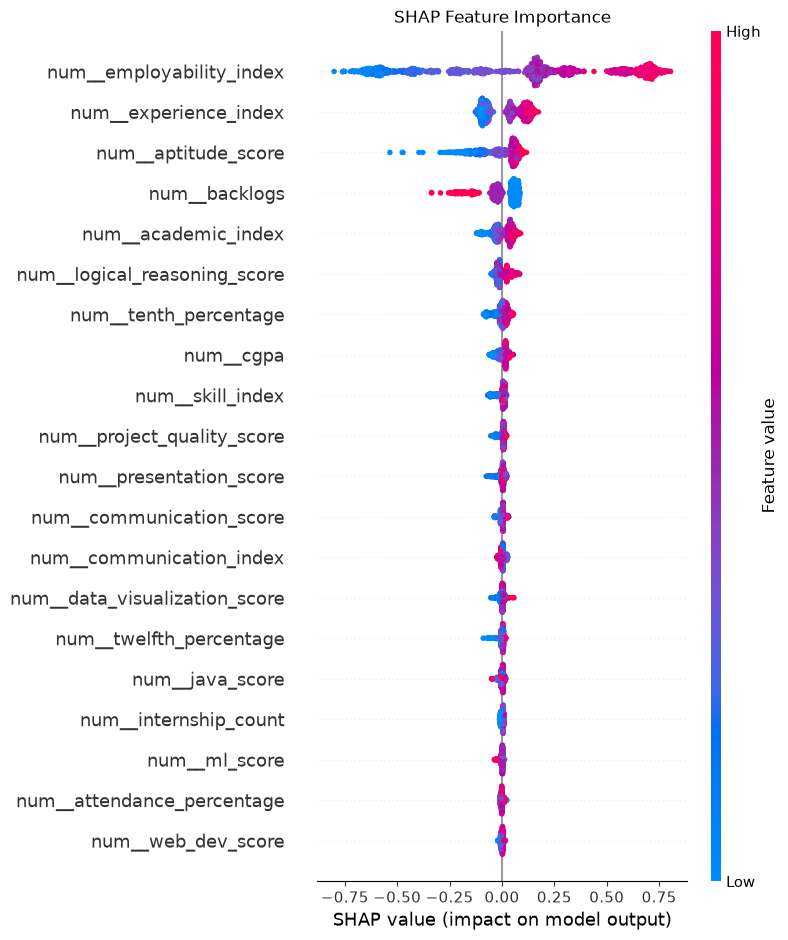

In [12]:
shap.summary_plot(
    shap_values,
    X_sample,
    feature_names=feature_names,
    show=False
)

plt.title(
    "SHAP Feature Importance"
)

plt.tight_layout()
plt.show()

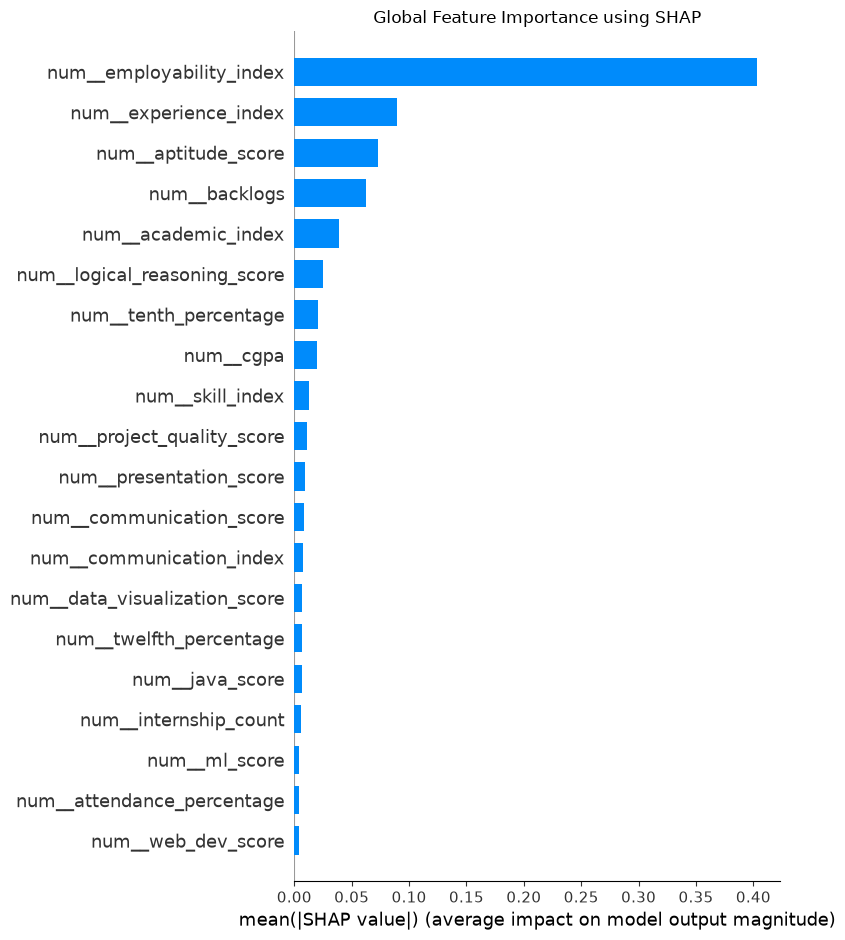

In [13]:
shap.summary_plot(
    shap_values,
    X_sample,
    feature_names=feature_names,
    plot_type="bar",
    show=False
)

plt.title(
    "Global Feature Importance using SHAP"
)

plt.tight_layout()
plt.show()

In [14]:
importance = np.abs(
    shap_values
).mean(axis=0)

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": importance
})

feature_importance = (
    feature_importance
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
)

In [15]:
feature_importance.head(20)

,feature,mean_abs_shap
33,num__employability_index,0.403027
31,num__experience_index,0.089816
17,num__aptitude_score,0.072655
4,num__backlogs,0.062804
29,num__academic_index,0.038531
18,num__logical_reasoning_score,0.024739
1,num__tenth_percentage,0.020438
3,num__cgpa,0.019681
30,num__skill_index,0.012965
28,num__project_quality_score,0.010883


In [16]:
feature_importance.to_csv(
    "../reports/shap_feature_importance.csv",
    index=False
)

print(
    "SHAP feature importance saved!"
)

SHAP feature importance saved!


In [17]:
student_index = 0

student = X.iloc[
    [student_index]
]

print(student)

   age gender       city      branch  tenth_percentage  twelfth_percentage  \
0   23   Male  Hyderabad  Mechanical             64.64               61.62   

   cgpa  backlogs  attendance_percentage  python_score  ...  \
0  6.41         3                  66.08         63.07  ...   

   work_experience_months  industry_projects  personal_projects  \
0                       0                  3                  1   

   certification_count  project_quality_score  academic_index  skill_index  \
0                    2                  54.14           63.99        55.14   

   experience_index  communication_index  employability_index  
0                38                79.08                59.27  

[1 rows x 37 columns]


In [18]:
prediction_probability = pipeline.predict_proba(
    student
)[0][1]

print(
    "Placement Probability:",
    round(
        prediction_probability * 100,
        2
    ),
    "%"
)

Placement Probability: 77.78 %


In [19]:
student_transformed = (
    preprocessor.transform(student)
)

In [20]:
student_shap = explainer.shap_values(
    student_transformed
)

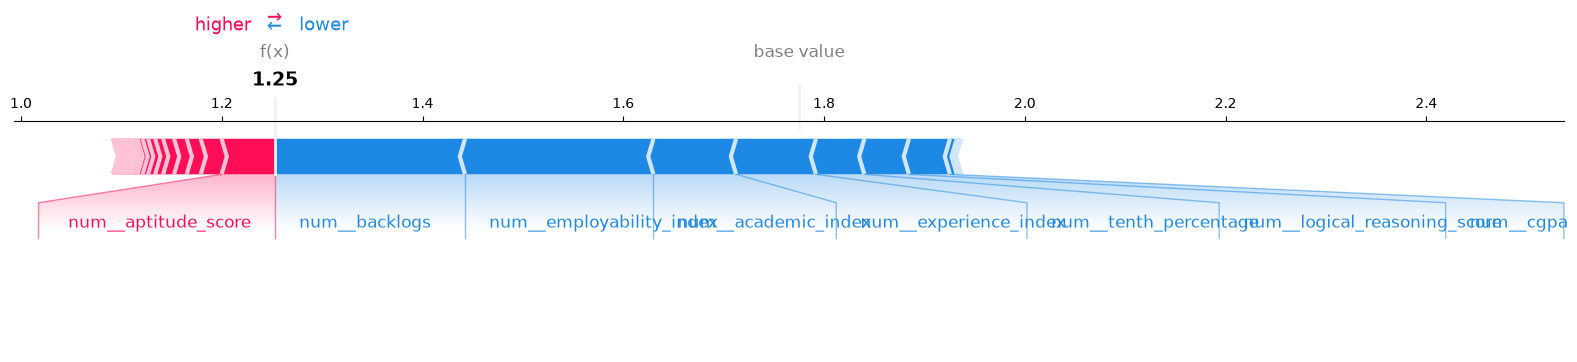

<Figure size 640x480 with 0 Axes>

In [21]:
shap.force_plot(
    explainer.expected_value,
    student_shap[0],
    feature_names=feature_names,
    matplotlib=True
)

plt.tight_layout()
plt.show()

In [22]:
student_contributions = pd.DataFrame({
    "feature": feature_names,
    "shap_value": student_shap[0]
})

In [23]:
student_contributions["absolute_impact"] = (
    student_contributions["shap_value"]
    .abs()
)

student_contributions = (
    student_contributions
    .sort_values(
        "absolute_impact",
        ascending=False
    )
)

In [24]:
student_contributions.head(10)

,feature,shap_value,absolute_impact
4,num__backlogs,-0.189288,0.189288
33,num__employability_index,-0.187714,0.187714
29,num__academic_index,-0.082354,0.082354
31,num__experience_index,-0.079542,0.079542
17,num__aptitude_score,0.053184,0.053184
1,num__tenth_percentage,-0.048245,0.048245
18,num__logical_reasoning_score,-0.044440,0.044440
3,num__cgpa,-0.040853,0.040853
7,num__sql_score,0.020774,0.020774
12,num__java_score,0.013978,0.013978
